<a href="https://colab.research.google.com/github/ziadm8692-glitch/Data-Analysis-and-AI--Portfolio/blob/main/Auto_Sales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_orginal=pd.read_csv('/content/Auto Sales data.csv'
)
df=df_orginal.copy()
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,24/02/2018,828,Shipped,Motorcycles,95,S10_1678,Land of Toys Inc.,2125557818,897 Long Airport Avenue,NYC,10022,USA,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,07/05/2018,757,Shipped,Motorcycles,95,S10_1678,Reims Collectables,26.47.1555,59 rue de l'Abbaye,Reims,51100,France,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,01/07/2018,703,Shipped,Motorcycles,95,S10_1678,Lyon Souveniers,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,Paris,75508,France,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,25/08/2018,649,Shipped,Motorcycles,95,S10_1678,Toys4GrownUps.com,6265557265,78934 Hillside Dr.,Pasadena,90003,USA,Young,Julie,Medium
4,10168,36,96.66,1,3479.76,28/10/2018,586,Shipped,Motorcycles,95,S10_1678,Technics Stores Inc.,6505556809,9408 Furth Circle,Burlingame,94217,USA,Hirano,Juri,Medium


# ***Data_Cleaing***

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2747 entries, 0 to 2746
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ORDERNUMBER           2747 non-null   int64  
 1   QUANTITYORDERED       2747 non-null   int64  
 2   PRICEEACH             2747 non-null   float64
 3   ORDERLINENUMBER       2747 non-null   int64  
 4   SALES                 2747 non-null   float64
 5   ORDERDATE             2747 non-null   object 
 6   DAYS_SINCE_LASTORDER  2747 non-null   int64  
 7   STATUS                2747 non-null   object 
 8   PRODUCTLINE           2747 non-null   object 
 9   MSRP                  2747 non-null   int64  
 10  PRODUCTCODE           2747 non-null   object 
 11  CUSTOMERNAME          2747 non-null   object 
 12  PHONE                 2747 non-null   object 
 13  ADDRESSLINE1          2747 non-null   object 
 14  CITY                  2747 non-null   object 
 15  POSTALCODE           

In [4]:
df.isna().sum()

,0
ORDERNUMBER,0
QUANTITYORDERED,0
PRICEEACH,0
ORDERLINENUMBER,0
SALES,0
ORDERDATE,0
DAYS_SINCE_LASTORDER,0
STATUS,0
PRODUCTLINE,0
MSRP,0


In [5]:
df.duplicated().sum()

np.int64(0)

In [7]:
Missing=['?','!','Missing','UnKnow','NA']
column=df.select_dtypes(include=['int64','object','float64']).columns
for col in column:
  for fake in Missing:
    count=(df[col]==fake).sum()
    if count > 0:
      print(f'These col is {col}, has a {fake}')

In [9]:
df_report=pd.DataFrame({"Colum":df.columns ,"Datype":df.dtypes.astype(str).values,"notnull":df.notna().sum(),"Isnull":df.isna().sum(),"Null pc":df.isnull().mean()*100})
df_report

,Colum,Datype,notnull,Isnull,Null pc
ORDERNUMBER,ORDERNUMBER,int64,2747,0,0.0
QUANTITYORDERED,QUANTITYORDERED,int64,2747,0,0.0
PRICEEACH,PRICEEACH,float64,2747,0,0.0
ORDERLINENUMBER,ORDERLINENUMBER,int64,2747,0,0.0
SALES,SALES,float64,2747,0,0.0
ORDERDATE,ORDERDATE,object,2747,0,0.0
DAYS_SINCE_LASTORDER,DAYS_SINCE_LASTORDER,int64,2747,0,0.0
STATUS,STATUS,object,2747,0,0.0
PRODUCTLINE,PRODUCTLINE,object,2747,0,0.0
MSRP,MSRP,int64,2747,0,0.0


In [10]:
df.columns

Index(['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER',
       'SALES', 'ORDERDATE', 'DAYS_SINCE_LASTORDER', 'STATUS', 'PRODUCTLINE',
       'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE', 'ADDRESSLINE1', 'CITY',
       'POSTALCODE', 'COUNTRY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME',
       'DEALSIZE'],
      dtype='object')

In [13]:
df.dtypes

,0
ORDERNUMBER,int64
QUANTITYORDERED,int64
PRICEEACH,float64
ORDERLINENUMBER,int64
SALES,float64
ORDERDATE,datetime64[ns]
DAYS_SINCE_LASTORDER,int64
STATUS,object
PRODUCTLINE,object
MSRP,int64


In [12]:
df['ORDERDATE']=pd.to_datetime(df['ORDERDATE'])


/tmp/ipykernel_1272/437648311.py:1: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['ORDERDATE']=pd.to_datetime(df['ORDERDATE'])


In [14]:
df['Order_M']=df['ORDERDATE'].dt.month
df['Order_Y']=df['ORDERDATE'].dt.year
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,...,PHONE,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE,Order_M,Order_Y
0,10107,30,95.70,2,2871.00,2018-02-24,828,Shipped,Motorcycles,95,...,2125557818,897 Long Airport Avenue,NYC,10022,USA,Yu,Kwai,Small,2,2018
1,10121,34,81.35,5,2765.90,2018-05-07,757,Shipped,Motorcycles,95,...,26.47.1555,59 rue de l'Abbaye,Reims,51100,France,Henriot,Paul,Small,5,2018
2,10134,41,94.74,2,3884.34,2018-07-01,703,Shipped,Motorcycles,95,...,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,Paris,75508,France,Da Cunha,Daniel,Medium,7,2018
3,10145,45,83.26,6,3746.70,2018-08-25,649,Shipped,Motorcycles,95,...,6265557265,78934 Hillside Dr.,Pasadena,90003,USA,Young,Julie,Medium,8,2018
4,10168,36,96.66,1,3479.76,2018-10-28,586,Shipped,Motorcycles,95,...,6505556809,9408 Furth Circle,Burlingame,94217,USA,Hirano,Juri,Medium,10,2018


In [16]:
df.drop(columns=['ORDERNUMBER','POSTALCODE','PHONE','ADDRESSLINE1','ORDERLINENUMBER']).columns

Index(['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'ORDERDATE',
       'DAYS_SINCE_LASTORDER', 'STATUS', 'PRODUCTLINE', 'MSRP', 'PRODUCTCODE',
       'CUSTOMERNAME', 'CITY', 'COUNTRY', 'CONTACTLASTNAME',
       'CONTACTFIRSTNAME', 'DEALSIZE', 'Order_M', 'Order_Y'],
      dtype='object')

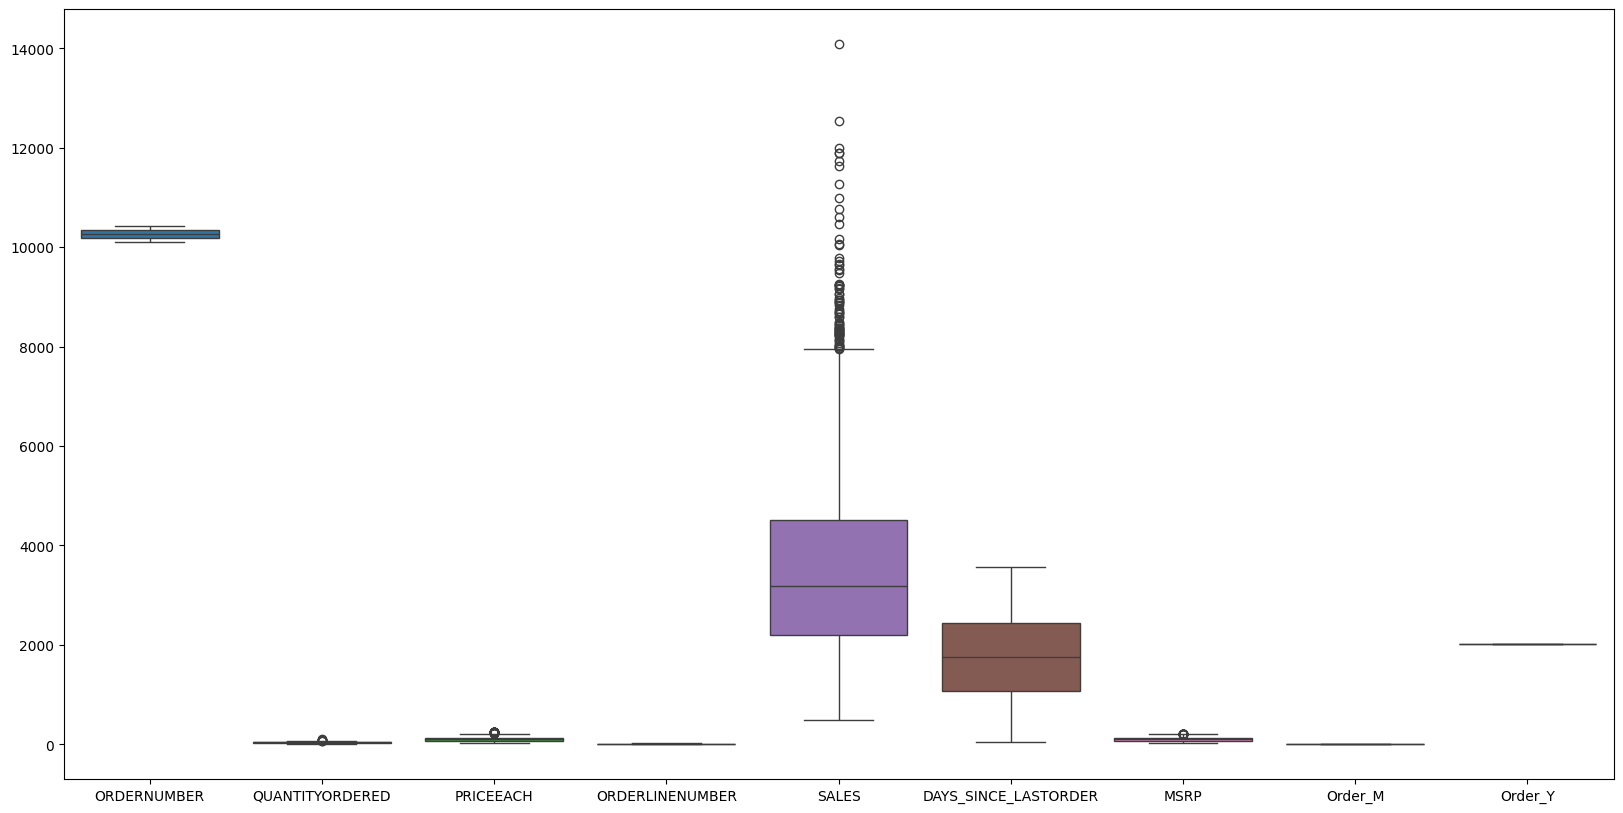

In [19]:
plt.figure(figsize=(20,10))
sns.boxplot(df.select_dtypes(np.number))
plt.show()

# ***EDA***

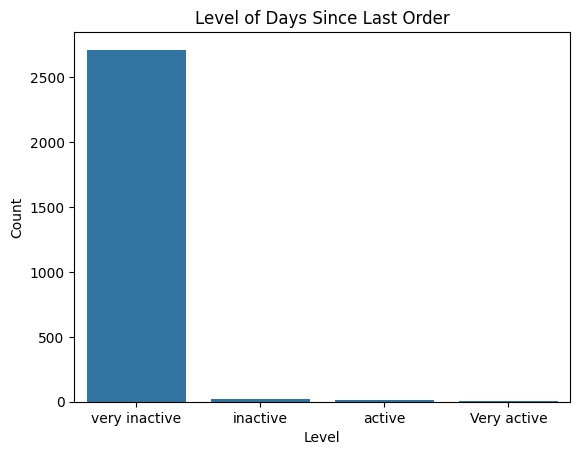

In [63]:
def Level_DAYS_SINCE_LASTORDER(days):
    if 42 <= days <= 76:
        return 'Very active'
    elif 79 <= days <= 150:
        return 'active'
    elif 151 <= days <= 250:
        return 'inactive'
    elif days >= 251:
        return 'very inactive'
    else:
        return 'other'

df['Level_DAYS_SINCE_LASTORDER'] = df['DAYS_SINCE_LASTORDER'].apply(Level_DAYS_SINCE_LASTORDER)

sns.countplot(data=df, x='Level_DAYS_SINCE_LASTORDER')
plt.title('Level of Days Since Last Order')
plt.xlabel('Level')
plt.ylabel('Count')

plt.show()

In [25]:
df['Discount_from_the_suggested_price']=(df['PRICEEACH']-df['MSRP'])/df['MSRP']*100

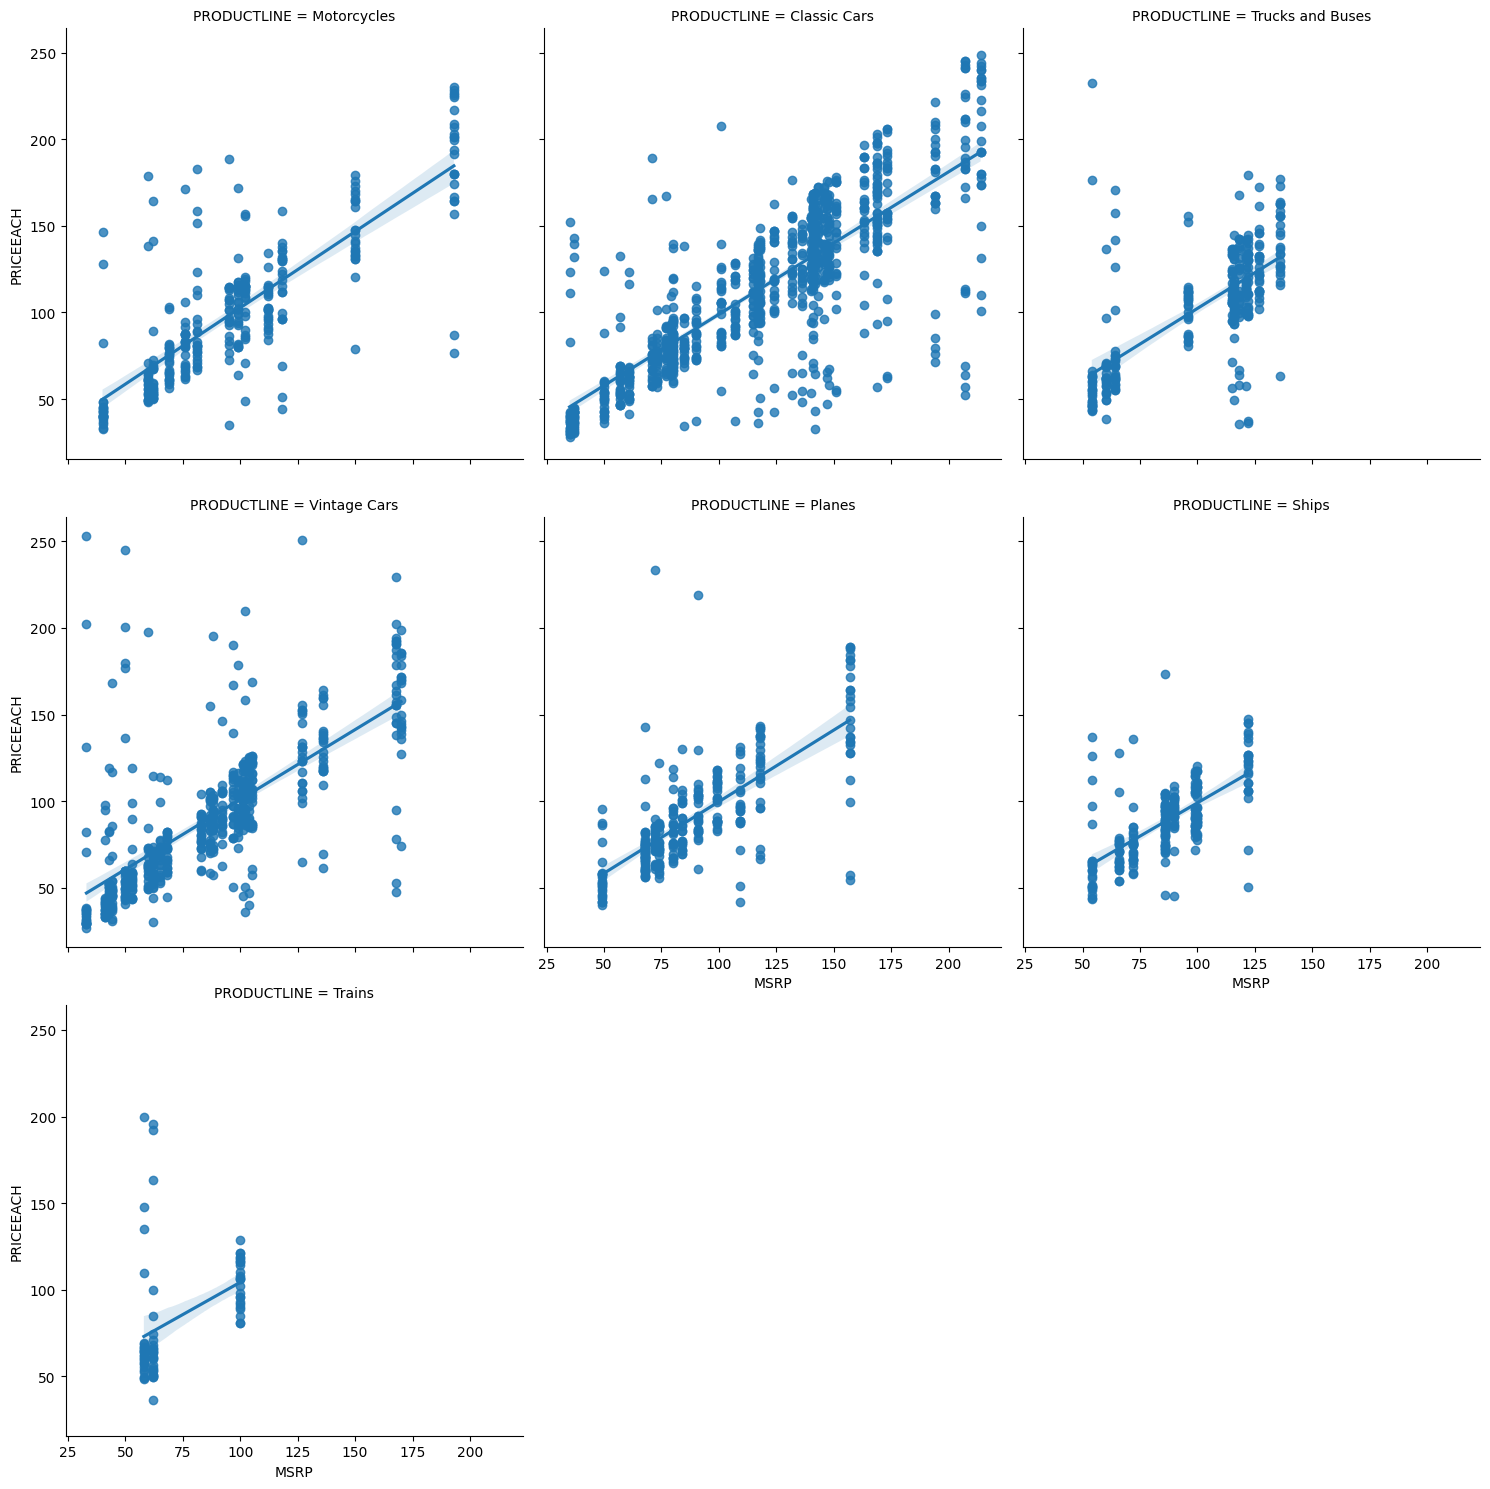

In [34]:
sns.lmplot(x='MSRP', y='PRICEEACH', col='PRODUCTLINE', data=df, col_wrap=3)
plt.show()

In [35]:
df['Discount_from_the_suggested_price_Group']=pd.qcut(df['Discount_from_the_suggested_price'],3,labels=['low','medium','high'])

In [40]:
PRODUCTLINE_Mode=df.groupby('PRODUCTLINE').agg(Order=('ORDERNUMBER','size'),Total_Sum=('SALES','sum'),Qun_Count=('QUANTITYORDERED','sum'),PRICEEACH_Avg=('PRICEEACH','median'),MSRP_Avg=('MSRP','median'),Discount_from_the_suggested_price_Avg=('Discount_from_the_suggested_price','median'))
PRODUCTLINE_Mode

,Order,Total_Sum,Qun_Count,PRICEEACH_Avg,MSRP_Avg,Discount_from_the_suggested_price_Avg
PRODUCTLINE,,,,,,
Classic Cars,949,3842868.54,33373,117.33,124.0,-2.066667
Motorcycles,313,1103512.19,11080,93.54,95.0,1.633929
Planes,304,969323.42,10636,83.32,80.0,2.196741
Ships,230,700039.22,7989,87.11,86.0,2.720930
Trains,77,226243.47,2712,67.73,62.0,5.880000
Trucks and Buses,295,1111559.19,10579,109.96,116.0,0.577586
Vintage Cars,579,1806675.68,20059,85.75,87.0,1.441176


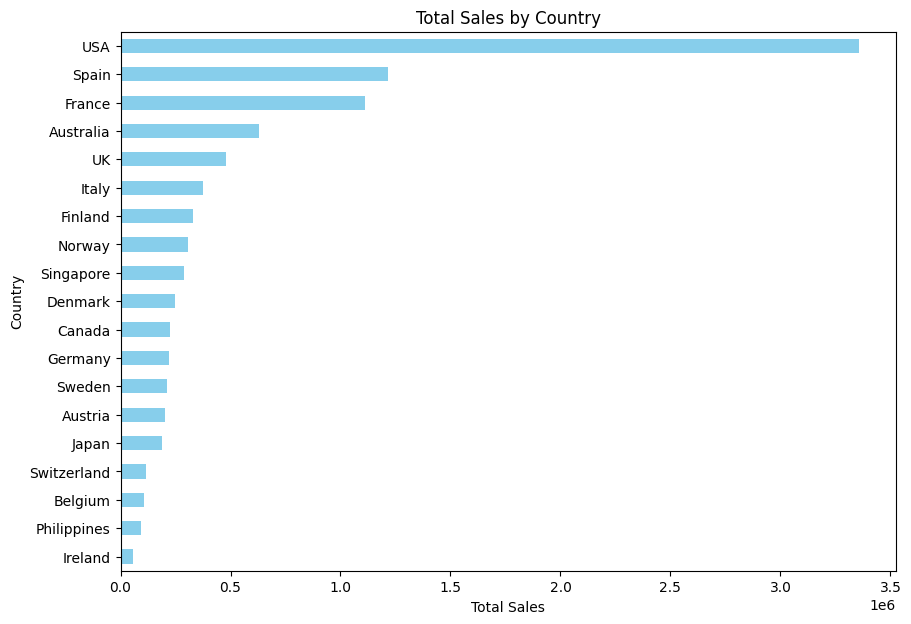

In [44]:
country_sales=(df.groupby('COUNTRY')['SALES'].sum().sort_values())
plt.figure(figsize=(10, 7))
country_sales.plot(kind='barh', color='skyblue')
plt.xlabel('Total Sales')
plt.ylabel('Country')
plt.title('Total Sales by Country')
plt.show()

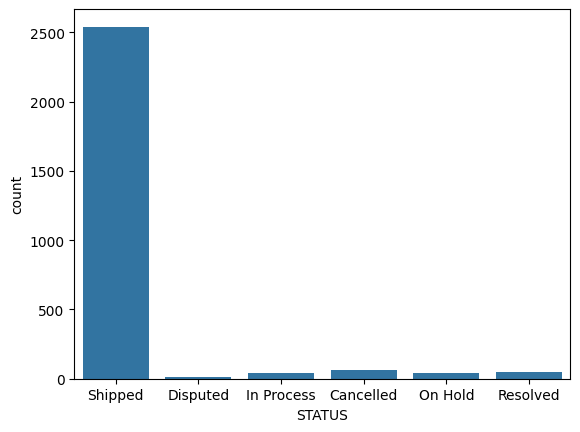

In [45]:
sns.countplot(x=df['STATUS'],data=df)
plt.show()


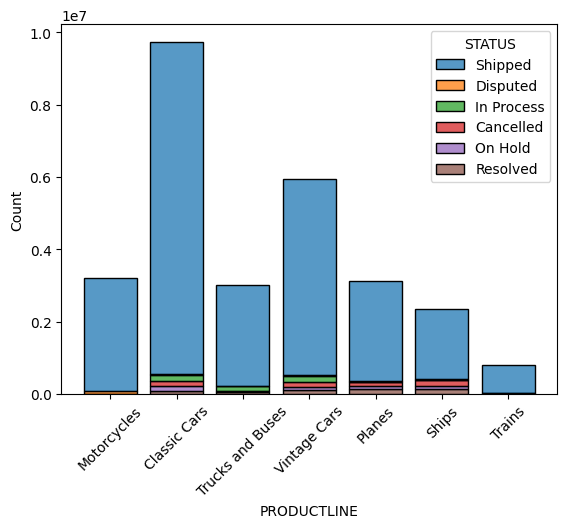

In [47]:
sns.histplot(x='PRODUCTLINE',hue='STATUS',data=df,multiple='stack',weights='ORDERNUMBER',shrink=0.8)
plt.xticks(rotation=45)

plt.show()

In [48]:
cancele_df=df[df['STATUS']=='Cancelled']
cancele_df


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,...,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE,Order_M,Order_Y,Level_DAYS_SINCE_LASTORDER,Discount_from_the_suggested_price,Discount_from_the_suggested_price_Group
103,10167,44,134.64,9,5924.16,2018-10-23,690,Cancelled,Classic Cars,136,...,S-844 67,Sweden,Larsson,Maria,Medium,10,2018,very inactive,-1.000000,medium
108,10248,20,145.52,3,2910.40,2019-05-07,499,Cancelled,Classic Cars,136,...,10022,USA,Yu,Kwai,Small,5,2019,very inactive,7.000000,medium
161,10253,24,163.44,13,3922.56,2019-06-01,527,Cancelled,Classic Cars,194,...,WX1 6LT,UK,Devon,Elizabeth,Medium,6,2019,very inactive,-15.752577,low
286,10253,22,109.22,11,2402.84,2019-06-01,652,Cancelled,Classic Cars,117,...,WX1 6LT,UK,Devon,Elizabeth,Small,6,2019,very inactive,-6.649573,medium
336,10253,25,90.17,14,2254.25,2019-06-01,702,Cancelled,Classic Cars,79,...,WX1 6LT,UK,Devon,Elizabeth,Small,6,2019,very inactive,14.139241,high
387,10253,41,119.77,10,4910.57,2019-06-01,753,Cancelled,Classic Cars,115,...,WX1 6LT,UK,Devon,Elizabeth,Medium,6,2019,very inactive,4.147826,medium
439,10253,26,117.48,5,3054.48,2019-06-01,805,Cancelled,Classic Cars,141,...,WX1 6LT,UK,Devon,Elizabeth,Medium,6,2019,very inactive,-16.680851,low
513,10253,24,140.62,1,3374.88,2019-06-01,879,Cancelled,Classic Cars,124,...,WX1 6LT,UK,Devon,Elizabeth,Medium,6,2019,very inactive,13.403226,high
531,10167,43,134.04,1,5763.72,2018-10-23,1118,Cancelled,Planes,157,...,S-844 67,Sweden,Larsson,Maria,Medium,10,2018,very inactive,-14.624204,low
538,10262,49,134.04,9,6567.96,2019-06-24,881,Cancelled,Planes,157,...,28034,Spain,Freyre,Diego,Medium,6,2019,very inactive,-14.624204,low


In [51]:
cancele_df['Cancelled_Level']=pd.qcut(cancele_df['QUANTITYORDERED'],3,labels=['low','medium','high'])

/tmp/ipykernel_1272/1463356157.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



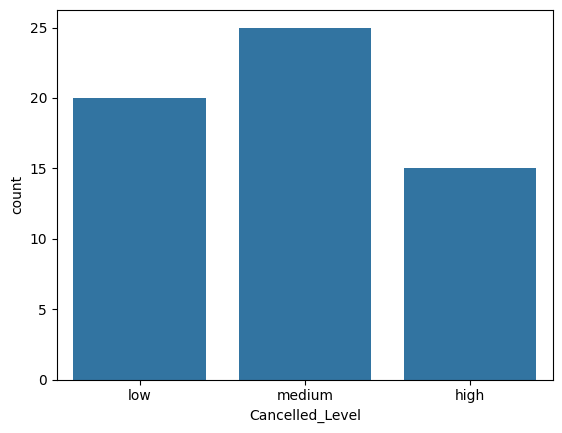

In [53]:
sns.countplot(x='Cancelled_Level',data=cancele_df.sort_values('Cancelled_Level'))
plt.show()
#

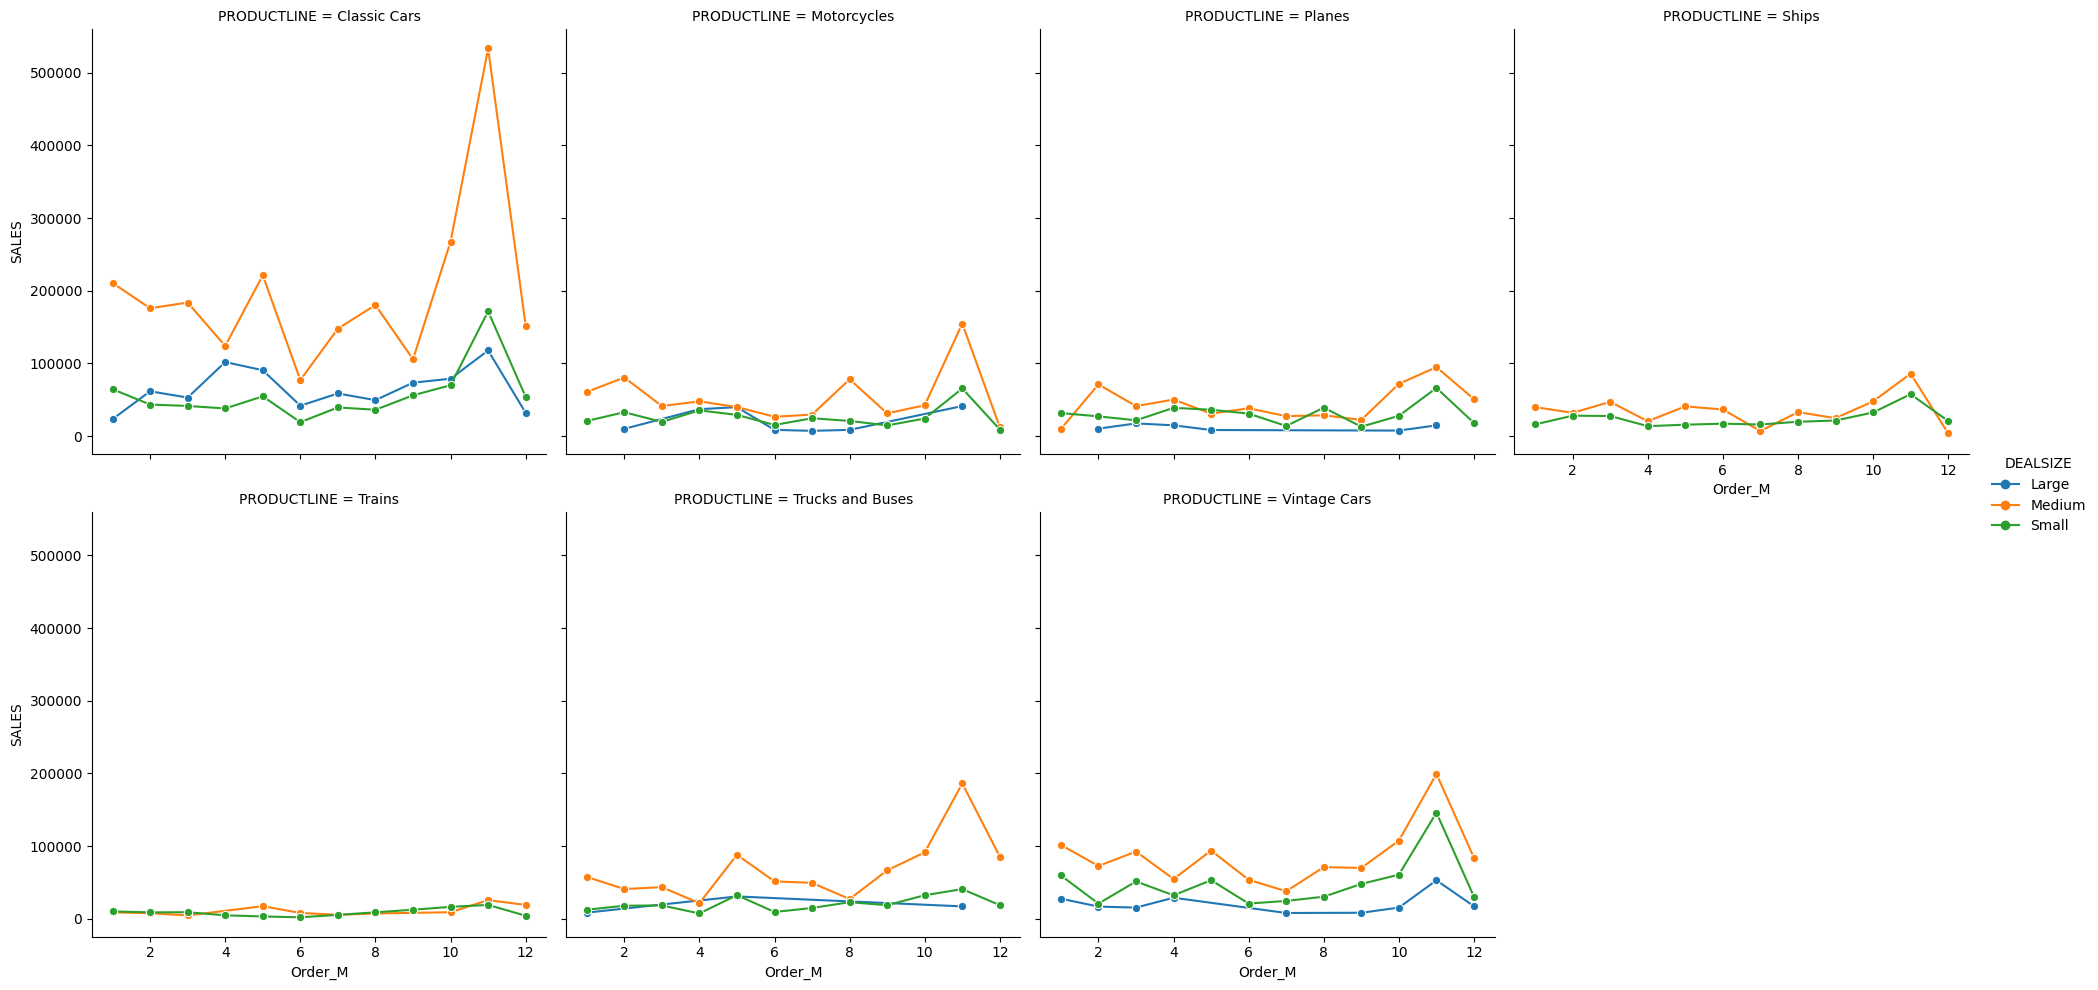

In [62]:
monthly = (df.groupby(['Order_M', 'PRODUCTLINE', 'DEALSIZE'])['SALES']
             .sum()).reset_index()

sns.relplot(x='Order_M', y='SALES', hue='DEALSIZE', data=monthly,
            kind='line', col='PRODUCTLINE', col_wrap=4, marker='o')
plt.show()